# Model 5 — Lasso regression, Cases 1–3

**Idea:** the same linear equation as MLR, ŷ = β₀ + β₁x₁ + … + βₚxₚ, but β is chosen to minimise

  (1 / 2n) · Σ(y − ŷ)² + α · Σ|βᵢ|

The L1 penalty (absolute values) can push coefficients to **exactly 0**, so Lasso also selects inputs:
any input with β = 0 is dropped from the model. Ridge's L2 penalty only shrinks coefficients, never to 0.
With α = 0, Lasso is exactly MLR.

- **Scaling:** inputs are standardised first (mean 0, std 1); the scaler is fitted on training data only.
- **Tuning:** α is chosen per case by the lowest validation RMSE. The test set is not used for the choice.

Same data, inputs, split, scoring window and metrics as the MLR and Ridge notebooks.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 1. Settings

In [2]:
# Works whether the notebook is opened from src/ or from the project folder.
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
CLEAN_CSV = ROOT / "Data" / "Clean" / "Winter_Clean.csv"
RESULTS = ROOT / "results"

CAPACITY_MW = 21.5
BAND_MW = 0.07 * CAPACITY_MW  # ±7% of capacity (GERC 2019 tolerance) = 1.505 MW

# Scoring window 07:00-18:15 (blocks 29-74): the plant never generates outside it.
DAY_FIRST_BLOCK, DAY_LAST_BLOCK = 29, 74

# Chronological split by target day (dates inclusive).
SPLITS = {
    "train": ("2025-10-15", "2026-01-14"),
    "val": ("2026-01-15", "2026-02-07"),
    "test": ("2026-02-08", "2026-02-14"),
}

# Short names for the CSV columns.
RENAME = {
    "Act. Power (MW)": "power",
    "W-GHI (W/m2)": "ghi",
    "W-MODT- (°C)": "modt",
    "W-AMBT (°C)": "ambt",
    "W-WSPD (m/s)": "wspd",
    "W-WDIR- (Degree)": "wdir",
}
WEATHER = ["ghi", "modt", "ambt", "wspd", "wdir"]

CASES = {
    "Case 1": ["power_D"],
    "Case 2": ["power_D"] + [f"{w}_D" for w in WEATHER],
    "Case 3": ["power_D"] + [f"{w}_D" for w in WEATHER] + [f"{w}_D+1" for w in WEATHER],
}

# Candidate penalty strengths: 0.0001 to 10, four per factor of 10.
ALPHAS = np.logspace(-4, 1, 21)

## 2. Load the clean data and label each day with its split

In [3]:
df = pd.read_csv(CLEAN_CSV, parse_dates=["TimeStamp", "Date"]).rename(columns=RENAME)

df["split"] = None
for name, (start, end) in SPLITS.items():
    df.loc[df["Date"].between(start, end), "split"] = name
assert df["split"].notna().all(), "some dates fall outside every split"

df.groupby("split")["Date"].agg(["min", "max", "nunique"]).loc[["train", "val", "test"]]

,min,max,nunique
split,,,
train,2025-10-15,2026-01-14,92
val,2026-01-15,2026-02-07,24
test,2026-02-08,2026-02-14,7


## 3. Build the inputs (identical to MLR)

`_D` = value at the same block on the previous day, `_D+1` = value on the target day (Case 3 only).

In [4]:
by_block = df.groupby("Block")
for col in ["power"] + WEATHER:
    df[f"{col}_D"] = by_block[col].shift(1)
for w in WEATHER:
    df[f"{w}_D+1"] = df[w]

# 15 Oct has no previous day, so it has no inputs.
df = df.dropna(subset=["power_D"]).reset_index(drop=True)

daytime = df[df["Block"].between(DAY_FIRST_BLOCK, DAY_LAST_BLOCK)].copy()
train = daytime[daytime["split"] == "train"]
val = daytime[daytime["split"] == "val"]

print("daytime rows per split:", daytime["split"].value_counts()[["train", "val", "test"]].to_dict())

daytime rows per split: {'train': 4186, 'val': 1104, 'test': 322}


## 4. Metrics

In [5]:
def evaluate(actual, forecast):
    err = forecast - actual
    mae = err.abs().mean()
    rmse = np.sqrt((err**2).mean())
    # R² = 1 - SS_res / SS_tot: share of variation explained vs always predicting the mean.
    r2 = 1 - (err**2).sum() / ((actual - actual.mean()) ** 2).sum()
    return {
        "MAE (MW)": mae,
        "RMSE (MW)": rmse,
        "nMAE (%)": 100 * mae / CAPACITY_MW,
        "nRMSE (%)": 100 * rmse / CAPACITY_MW,
        "Within ±7% (%)": 100 * (err.abs() <= BAND_MW).mean(),
        "R² (%)": 100 * r2,
        "Blocks": len(err),
    }


def skill_score(rmse, rmse_persistence):
    # 0 = no better than persistence, positive = better, negative = worse.
    return 100 * (1 - rmse / rmse_persistence)


def lasso_model(alpha):
    # Scaler + Lasso in one object: fit() learns the scaling from the data it is given (training only).
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50_000))

## 5. Tune α on validation

For each case and each candidate α: fit on training, predict validation, record training and validation RMSE, the coefficients, and how many inputs are still used (β ≠ 0).
The α with the lowest validation RMSE is kept.

In [6]:
search = []
for case, features in CASES.items():
    for alpha in ALPHAS:
        model = lasso_model(alpha).fit(train[features], train["power"])
        train_pred = np.clip(model.predict(train[features]), 0, CAPACITY_MW)
        val_pred = np.clip(model.predict(val[features]), 0, CAPACITY_MW)
        search.append({
            "case": case,
            "alpha": alpha,
            "train RMSE (MW)": evaluate(train["power"], train_pred)["RMSE (MW)"],
            "val RMSE (MW)": evaluate(val["power"], val_pred)["RMSE (MW)"],
            "inputs used": int((model[-1].coef_ != 0).sum()),
            # standardised coefficients at this α (for the website's slider)
            **{f"coef {f}": c + 0.0 for f, c in zip(features, model[-1].coef_)},
        })
search = pd.DataFrame(search)

best = search.loc[search.groupby("case")["val RMSE (MW)"].idxmin()].set_index("case")
best[["alpha", "train RMSE (MW)", "val RMSE (MW)", "inputs used"]]

,alpha,train RMSE (MW),val RMSE (MW),inputs used
case,,,,
Case 1,0.177828,1.838844,2.092511,1
Case 2,0.010000,1.791457,2.037803,5
Case 3,0.000100,1.141669,1.522274,11


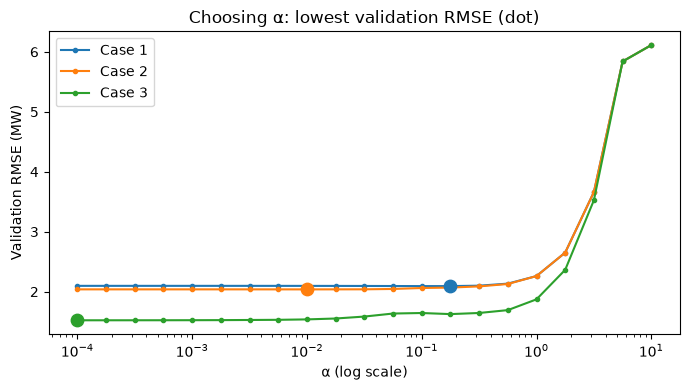

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for case, part in search.groupby("case"):
    ax.plot(part["alpha"], part["val RMSE (MW)"], marker=".", label=case)
    ax.scatter(best.loc[case, "alpha"], best.loc[case, "val RMSE (MW)"], s=80, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("α (log scale)")
ax.set_ylabel("Validation RMSE (MW)")
ax.set_title("Choosing α: lowest validation RMSE (dot)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Fit the final model per case with its chosen α

In [8]:
models = {}
for case, features in CASES.items():
    model = lasso_model(best.loc[case, "alpha"]).fit(train[features], train["power"])
    daytime[case] = np.clip(model.predict(daytime[features]), 0, CAPACITY_MW)
    models[case] = model

## 7. Scores: every case on every split

In [9]:
rows = []
for case in CASES:
    for split in ["train", "val", "test"]:
        part = daytime[daytime["split"] == split]
        scores = evaluate(part["power"], part[case])
        rmse_persistence = evaluate(part["power"], part["power_D"])["RMSE (MW)"]
        rows.append({
            "case": case,
            "alpha": best.loc[case, "alpha"],
            "split": split,
            **scores,
            "Skill vs persistence (%)": skill_score(scores["RMSE (MW)"], rmse_persistence),
        })

metrics = pd.DataFrame(rows).round(3)
metrics

,case,alpha,split,MAE (MW),RMSE (MW),nMAE (%),nRMSE (%),Within ±7% (%),R² (%),Blocks,Skill vs persistence (%)
0,Case 1,0.178,train,1.092,1.839,5.078,8.553,82.967,91.184,4186,0.657
1,Case 1,0.178,val,1.292,2.093,6.011,9.733,76.993,88.204,1104,1.902
2,Case 1,0.178,test,0.995,1.270,4.630,5.908,79.193,95.872,322,-9.294
3,Case 2,0.010,train,1.030,1.791,4.793,8.332,82.824,91.632,4186,3.217
4,Case 2,0.010,val,1.255,2.038,5.836,9.478,77.264,88.813,1104,4.466
5,Case 2,0.010,test,0.869,1.176,4.043,5.471,83.230,96.460,322,-1.218
6,Case 3,0.000,train,0.807,1.142,3.752,5.310,84.687,96.602,4186,38.321
7,Case 3,0.000,val,1.090,1.522,5.072,7.080,75.725,93.757,1104,28.635
8,Case 3,0.000,test,0.820,1.072,3.812,4.986,84.161,97.061,322,7.770


Validation only, side by side (this is the table used to compare models):

In [10]:
metrics[metrics["split"] == "val"].set_index("case").drop(columns=["split", "Blocks"])

,alpha,MAE (MW),RMSE (MW),nMAE (%),nRMSE (%),Within ±7% (%),R² (%),Skill vs persistence (%)
case,,,,,,,,
Case 1,0.178,1.292,2.093,6.011,9.733,76.993,88.204,1.902
Case 2,0.010,1.255,2.038,5.836,9.478,77.264,88.813,4.466
Case 3,0.000,1.090,1.522,5.072,7.080,75.725,93.757,28.635


## 8. Coefficients

Inputs are standardised, so each coefficient is the change in forecast (MW) for a **1 standard deviation** rise in that input.
A coefficient of exactly 0 means the model dropped that input.

In [11]:
coefs = pd.DataFrame({
    case: pd.Series(m[-1].coef_, index=m[0].feature_names_in_) for case, m in models.items()
})
coefs.loc["intercept"] = [m[-1].intercept_ for m in models.values()]
coefs = coefs.reindex(["intercept"] + CASES["Case 3"]) + 0.0  # + 0.0 turns -0.0 into 0.0
print("Inputs dropped (β = 0):", {case: list(coefs.index[coefs[case] == 0]) for case in CASES})
coefs.round(4)

Inputs dropped (β = 0): {'Case 1': [], 'Case 2': ['wdir_D'], 'Case 3': []}


,Case 1,Case 2,Case 3
intercept,10.2015,10.2015,10.2015
power_D,5.7386,4.6970,3.8536
ghi_D,NaN,0.5847,-1.9378
modt_D,NaN,1.1380,0.0717
ambt_D,NaN,-0.7077,-0.7740
wspd_D,NaN,0.0180,-0.0020
wdir_D,NaN,0.0000,0.0124
ghi_D+1,NaN,NaN,3.2540
modt_D+1,NaN,NaN,1.5905
ambt_D+1,NaN,NaN,-0.2168


How the Case 3 coefficients shrink as α grows. Far left ≈ plain MLR; lines hitting 0 are inputs being dropped. The dashed line is the chosen α.

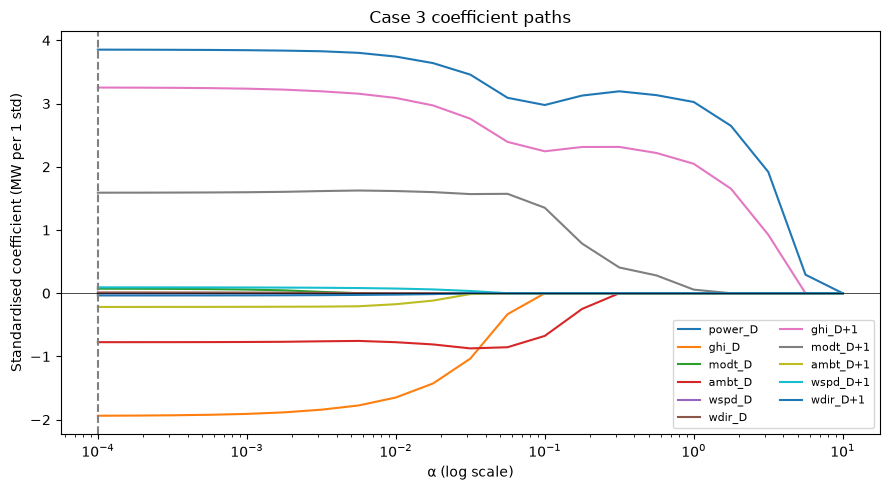

In [12]:
features = CASES["Case 3"]
path = pd.DataFrame(
    [lasso_model(a).fit(train[features], train["power"])[-1].coef_ for a in ALPHAS],
    index=ALPHAS, columns=features,
)

fig, ax = plt.subplots(figsize=(9, 5))
for col in features:
    ax.plot(path.index, path[col], label=col)
ax.axvline(best.loc["Case 3", "alpha"], color="grey", linestyle="--")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("α (log scale)")
ax.set_ylabel("Standardised coefficient (MW per 1 std)")
ax.set_title("Case 3 coefficient paths")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 9. Where does it fail? Worst validation days (Case 2, the realistic case)

In [13]:
daily_mae = (
    daytime[daytime["split"] == "val"]
    .assign(abs_err=lambda x: (x["Case 2"] - x["power"]).abs())
    .groupby("Date")["abs_err"]
    .mean()
    .round(2)
)
daily_mae.sort_values(ascending=False).head(5)

Date
2026-01-26    3.93
2026-01-27    3.72
2026-01-30    2.42
2026-01-23    2.14
2026-01-21    1.75
Name: abs_err, dtype: float64

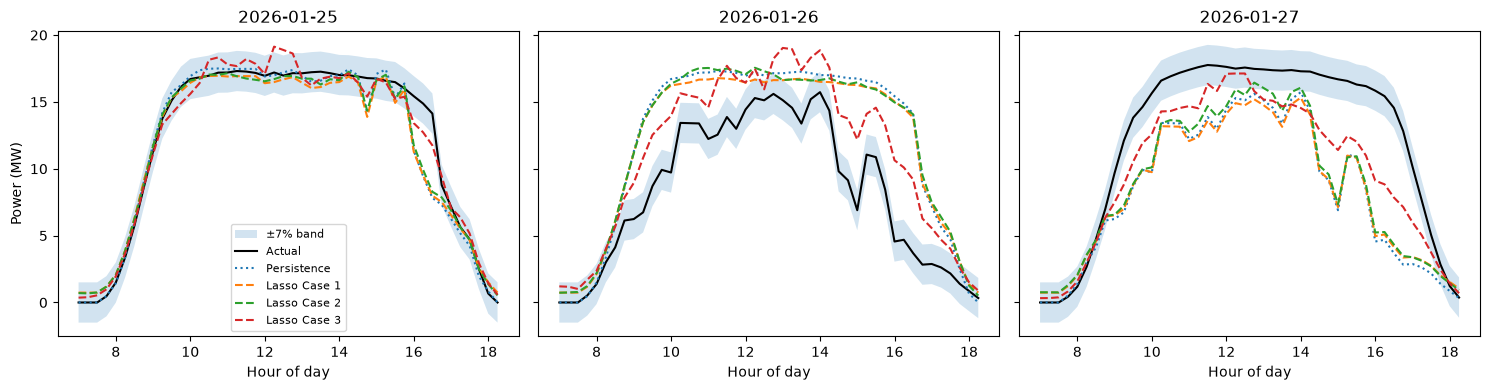

In [14]:
# Same three validation days as the other notebooks: clear, cloudy, clear.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, day in zip(axes, ["2026-01-25", "2026-01-26", "2026-01-27"]):
    d = daytime[daytime["Date"] == day]
    hours = (d["Block"] - 1) / 4
    ax.fill_between(hours, d["power"] - BAND_MW, d["power"] + BAND_MW, alpha=0.2, label="±7% band")
    ax.plot(hours, d["power"], color="black", label="Actual")
    ax.plot(hours, d["power_D"], ":", label="Persistence")
    for case in CASES:
        ax.plot(hours, d[case], "--", label=f"Lasso {case}")
    ax.set_title(day)
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Power (MW)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Save forecasts, scores and the search

In [15]:
(RESULTS / "predictions").mkdir(parents=True, exist_ok=True)
(RESULTS / "metrics").mkdir(parents=True, exist_ok=True)

# Every block, with night forecasts set to 0.
out = df[["TimeStamp", "Date", "Block", "split", "power"]].rename(columns={"power": "actual"})
for case in CASES:
    out[f"Lasso {case}"] = daytime[case].reindex(out.index).fillna(0.0)

out.to_csv(RESULTS / "predictions" / "lasso.csv", index=False)
metrics.to_csv(RESULTS / "metrics" / "lasso.csv", index=False)
coefs.to_csv(RESULTS / "metrics" / "lasso_coefficients.csv")
search.to_csv(RESULTS / "metrics" / "lasso_search.csv", index=False)